# Лабораторная 6. Остаточные свёрточные сети. Дроп-аут. Батч-нормализация

**Задание.**

*1. Архитектура.* Реализовать свёрточную сеть с блоками слоёв с соединениями
напрямую (остаточными блоками). Использовать свёрточные блоки различной
архитектуры: 1) свёрточные блоки из предыдущего задания; 2) свёрточные блоки с
соединениями напрямую; 3) bottleneck-блоки (свёртки $1 \times 1$); и слои:
1) пакетной нормализации (batchnorm), 2) дроп-аута (dropout).

*2. Выборки.* Использовать выборку CIFAR-10 или др. (MNIST, FashionMNIST - для
сравнения). Для выбранного датасета подобрать параметры, при которых для
построенной архитектуры достигается наивысшее качество классификации. Сравнить с
результатами свёрточной сети (не остаточной) на тех же выборках.

*3. Гиперпараметры:* количество эпох; коэффициент обучения; количество скрытых
слоёв (количество остаточных блоков); количество каналов; параметры kernel,
stride, padding преобразований Conv2d и MaxPool2d; количество скрытых слоёв и
нейронов в многослойном перцептроне на выходе сети.

## 1. Теория

### Данные

Основная выборка CIFAR-10: цветные изображения $32 \times 32$, три канала (красный,
зелёный, синий), 10 классов (самолёт, автомобиль, птица, кошка, олень, собака,
лягушка, лошадь, корабль, грузовик), 50000 обучающих и 10000 тестовых. MNIST и
FashionMNIST ($28 \times 28$, один канал) используются для сравнения.

Для перебора гиперпараметров из обучающей части CIFAR-10 берутся 5000
изображений для обучения и 2000 отложенных для оценки. Число эпох подбирается на
модели, обученной на 15000 изображениях. Тестовая выборка из 10000 изображений в
переборе не участвует. Яркости делятся на 255 и нормируются средним и стандартным
отклонением каждого канала по обучающей части.

### Блоки

- plain: две свёртки блока б) из лабораторной 5, Conv-ReLU-Conv-ReLU, без пуллинга
  и без соединения напрямую. Пуллинг убран, чтобы блоки можно было ставить подряд,
  не уменьшая карту признаков;
- residual: тот же блок с соединением напрямую, $y = \mathrm{ReLU}\bigl(F(x) + x\bigr)$,
  где $F$ это две свёртки блока;
- bottleneck: свёртки $1\times1$, $k\times k$, $1\times1$ с соединением напрямую,
  первая сжимает число каналов вчетверо, последняя возвращает его.

В блоках шаг 1 и дополнение $\lfloor k/2 \rfloor$, поэтому размер карты признаков не
меняется и $F(x)$ можно сложить с $x$. При батч-нормализации после каждой свёртки
блока стоит BatchNorm, дроп-аут ставится перед последней нормализацией.

### Сеть

Входной слой и переход между стадиями: свёртка, батч-нормализация, ReLU и
пуллинг, то есть блок а) из лабораторной 5 с батч-нормализацией (в варианте 3
ниже вместо пуллинга свёртка с шагом 2). Они уменьшают карту признаков вдвое.
Сеть: входной слой, первая стадия из блоков при $C$ каналах, переход с удвоением
числа каналов, вторая стадия из блоков при $2C$ каналах, усреднение по карте
признаков и многослойный перцептрон на выходе. Карта признаков уменьшается для
CIFAR-10 с 32 до 16 и до 8, для MNIST с 28 до 14 и до 7.

Неостаточная сеть для сравнения взята из лабораторной 5 с лучшими найденными там
параметрами: два блока а) Conv-ReLU-MaxPool, ядро свёртки 5, пуллинг с окном 2 и
шагом 2, SGD с коэффициентом обучения 0.01.

### Размер выхода свёртки и пуллинга

Для входа $n \times n$, ядра $k$, шага $s$ и дополнения $p$

$$n_{\text{out}} = \left\lfloor \frac{n + 2p - k}{s} \right\rfloor + 1 .$$

Уменьшение карты вдвое во входном слое и в переходе делается одним из способов
(kernel/stride/padding):

| Вариант | Conv2d | MaxPool2d |
|---|---|---|
| 1 | 3/1/1 | 2/2/0 |
| 2 | 3/1/1 | 3/2/1 |
| 3 | 3/2/1 | нет |
| 4 | 5/1/2 | 2/2/0 |

Во всех вариантах из 32 получается 16, из 28 получается 14.

### Батч-нормализация и дроп-аут

Батч-нормализация нормирует каждый канал по мини-батчу:

$$\hat z = \frac{z - \mu_B}{\sqrt{\sigma_B^2 + \varepsilon}}, \qquad
  y = \gamma\hat z + \beta,$$

где $\mu_B$ и $\sigma_B^2$ считаются по батчу, а $\gamma$, $\beta$ обучаются. При
применении сети вместо статистик батча берутся накопленные скользящие средние.

Дроп-аут при обучении обнуляет случайную долю $p$ каналов (`Dropout2d`) и
масштабирует оставшиеся, при применении сети пропускает всё.

### Что перебирается

| Гиперпараметр | Значения |
|---|---|
| тип блока | plain, residual, bottleneck |
| число блоков | 2, 4, 8 |
| батч-нормализация | есть, нет |
| дроп-аут | $0$, $0.2$, $0.5$ |
| число каналов $C$ | 16, 32 |
| коэффициент обучения | $0.01$, $0.05$, $0.1$ |
| Conv2d и MaxPool2d входного слоя и перехода | варианты 1-4 |
| размер ядра в блоках | 3, 5 |
| выходной перцептрон | без скрытых слоёв, $(64)$, $(128)$, $(128, 64)$ |
| число эпох | от 1 до 20 |

Перебор последовательный: на каждом этапе фиксируются лучшие значения
предыдущих. Настраивается остаточная сеть, поэтому тип блока выбирается из
residual и bottleneck, а plain участвует в переборе для сравнения. На этапах
перебора каждая конфигурация обучается 10 эпох, SGD с моментом 0.9, батчи по 64.
В таблицах обе точности взяты на эпохе с наибольшей accuracy на отложенной
выборке, точность на обучающей считается по 1000 её изображений.

Число эпох выбирается на сети с найденными параметрами, обученной 20 эпох на
15000 изображениях: берётся эпоха с наибольшей accuracy на отложенных 2000
изображениях, и в сети остаются веса с этой эпохи.

При сравнении на каждой из трёх выборок четыре сети (сеть из лабораторной 5 и
сети с найденными параметрами из блоков plain, residual, bottleneck) обучаются 10
эпох на 5000 изображениях, в них остаются веса с эпохи с наибольшей accuracy на
отложенных 2000 изображениях, и точность считается на тестовых 10000.

### Функция потерь и обучение

ReLU применяется к каждому элементу: $\mathrm{ReLU}(t) = \max(0, t)$. Выходы сети
$t_0, \ldots, t_9$ переводятся мягким максимумом в вероятности классов
$p_c = e^{t_c} / (e^{t_0} + \dots + e^{t_9})$, функция потерь - перекрёстная
энтропия $L = -\frac1n\sum_k \log p_{y_k}(x_k)$. Обучение - стохастический
градиентный спуск с моментом 0.9: после каждого батча

$$v \leftarrow 0.9\,v + g, \qquad w \leftarrow w - \eta v,$$

где $g$ - градиент функции потерь на батче, его находит torch методом обратного
распространения ошибки.

### Мера качества

Доля верных ответов $\mathrm{accuracy} = \frac1n \sum_k [\,\hat y_k = y_k\,]$.

## 2. Данные

In [1]:
import os
import struct
import tarfile
import itertools
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.backends.cudnn.deterministic = True  # одинаковые числа при перезапуске на GPU
plt.rcParams['figure.dpi'] = 110

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'torch {torch.__version__}, устройство: {DEVICE}')

torch 2.11.0+cu128, устройство: cuda


In [2]:
CIFAR_URL = 'https://www.cs.toronto.edu/~kriz/cifar-10-binary.tar.gz'
CIFAR_CLASSES = ['самолёт', 'автомобиль', 'птица', 'кошка', 'олень',
                 'собака', 'лягушка', 'лошадь', 'корабль', 'грузовик']


def cifar_dir():
    for c in [os.environ.get('CIFAR_DIR'), '../data/cifar-10-batches-bin',
              'data/cifar-10-batches-bin']:
        if c and Path(c, 'test_batch.bin').exists():
            return Path(c)
    # на диске нет: архив скачивается с сайта CIFAR и распаковывается в ../data
    Path('../data').mkdir(exist_ok=True)
    archive = Path('../data/cifar-10-binary.tar.gz')
    urllib.request.urlretrieve(CIFAR_URL, archive)
    with tarfile.open(archive) as tar:
        tar.extractall('../data', filter='data')
    return Path('../data/cifar-10-batches-bin')


def read_cifar(path):
    """Файл CIFAR-10: записи по 3073 байта, сначала метка, затем три канала 32 на 32."""
    raw = np.fromfile(path, dtype=np.uint8).reshape(-1, 3073)
    return raw[:, 1:].reshape(-1, 3, 32, 32), raw[:, 0]


def read_idx(path):
    with open(path, 'rb') as f:
        magic, = struct.unpack('>I', f.read(4))
        dims = struct.unpack('>' + 'I' * (magic & 0xff), f.read(4 * (magic & 0xff)))
        return np.frombuffer(f.read(), dtype=np.uint8).reshape(dims)


def mnist_like(name, env):
    """MNIST или FashionMNIST в той же форме, что CIFAR: (N, 1, 28, 28)."""
    for c in [os.environ.get(env), f'../data/{name}/raw', f'data/{name}/raw',
              '../../bachelor/Perceptron/data_generation/MNIST/raw' if name == 'MNIST' else None]:
        if c and Path(c, 'train-images-idx3-ubyte').exists():
            D = Path(c)
            # [:, None] добавляет ось канала
            return (read_idx(D / 'train-images-idx3-ubyte')[:, None], read_idx(D / 'train-labels-idx1-ubyte'),
                    read_idx(D / 't10k-images-idx3-ubyte')[:, None], read_idx(D / 't10k-labels-idx1-ubyte'))
    raise FileNotFoundError(name)


C = cifar_dir()
parts = [read_cifar(C / f'data_batch_{i}.bin') for i in range(1, 6)]
cifar = (np.concatenate([p[0] for p in parts]), np.concatenate([p[1] for p in parts]),
         *read_cifar(C / 'test_batch.bin'))
RAW = {'CIFAR-10': cifar,
       'FashionMNIST': mnist_like('FashionMNIST', 'FASHION_DIR'),
       'MNIST': mnist_like('MNIST', 'MNIST_DIR')}
for name, (Xtr, ytr, Xte, yte) in RAW.items():
    print(f'{name:12s} обучающая {Xtr.shape}, тестовая {Xte.shape}, классы {np.bincount(ytr)}')

CIFAR-10     обучающая (50000, 3, 32, 32), тестовая (10000, 3, 32, 32), классы [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]
FashionMNIST обучающая (60000, 1, 28, 28), тестовая (10000, 1, 28, 28), классы [6000 6000 6000 6000 6000 6000 6000 6000 6000 6000]
MNIST        обучающая (60000, 1, 28, 28), тестовая (10000, 1, 28, 28), классы [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


In [3]:
def split(name, n_train, n_val, rng):
    """Обучающая и отложенная подвыборки из обучающей части, тензоры на устройстве."""
    Xtr, ytr, Xte, yte = RAW[name]
    perm = rng.permutation(len(Xtr))
    itr, ival = perm[:n_train], perm[n_train:n_train + n_val]  # части не пересекаются
    # среднее и отклонение каждого канала: усреднение по объектам и по пикселям
    mean = Xtr.mean(axis=(0, 2, 3)) / 255.0
    std = Xtr.std(axis=(0, 2, 3)) / 255.0

    def to_tensor(X, y):
        t = torch.tensor(X, dtype=torch.float32) / 255.0
        # mean[:, None, None] растягивается на все пиксели своего канала
        t = (t - torch.tensor(mean[:, None, None], dtype=torch.float32)) / \
            torch.tensor(std[:, None, None], dtype=torch.float32)
        # .to(DEVICE) переносит тензоры на видеокарту, если она есть
        return t.to(DEVICE), torch.tensor(y, dtype=torch.long).to(DEVICE)

    return to_tensor(Xtr[itr], ytr[itr]), to_tensor(Xtr[ival], ytr[ival]), to_tensor(Xte, yte)


(Xc, yc), (Xcv, ycv), (Xct, yct) = split('CIFAR-10', 5000, 2000, np.random.default_rng(20260905))
print(f'перебор: обучающая {tuple(Xc.shape)}, отложенная {tuple(Xcv.shape)}, '
      f'тестовая {tuple(Xct.shape)}')

перебор: обучающая (5000, 3, 32, 32), отложенная (2000, 3, 32, 32), тестовая (10000, 3, 32, 32)


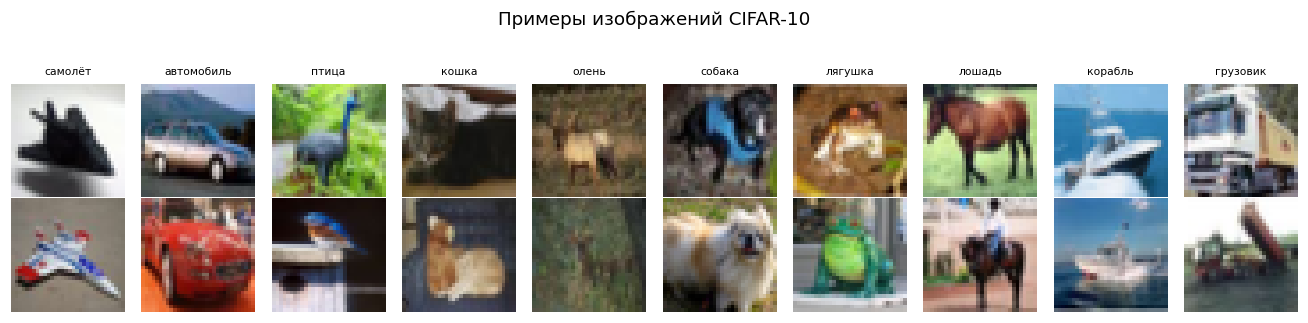

In [4]:
fig, axes = plt.subplots(2, 10, figsize=(12, 2.8))
Xr, yr = RAW['CIFAR-10'][0], RAW['CIFAR-10'][1]
for c in range(10):
    for row in range(2):
        j = np.flatnonzero(yr == c)[row]
        # imshow ждёт порядок осей (высота, ширина, канал), transpose переставляет оси
        axes[row, c].imshow(Xr[j].transpose(1, 2, 0))
        axes[row, c].axis('off')
    axes[0, c].set_title(CIFAR_CLASSES[c], fontsize=7)
fig.suptitle('Примеры изображений CIFAR-10', y=1.04)
plt.tight_layout()
plt.show()

## 3. Блоки и сети

In [5]:
def norm_layer(c, bn):
    """Батч-нормализация или пустышка, если нормализация выключена."""
    return nn.BatchNorm2d(c) if bn else nn.Identity()


class Block(nn.Module):
    """kind: plain - без соединения напрямую; residual - с соединением;
    bottleneck - свёртки 1x1 вокруг k x k, с соединением."""

    def __init__(self, c, kind='plain', ks=3, bn=True, dropout=0.0):
        super().__init__()
        pad = ks // 2
        if kind == 'bottleneck':
            mid = max(4, c // 4)  # внутри блока число каналов сжимается вчетверо
            layers = [nn.Conv2d(c, mid, 1), norm_layer(mid, bn), nn.ReLU(),
                      nn.Conv2d(mid, mid, ks, 1, pad), norm_layer(mid, bn), nn.ReLU(),
                      nn.Conv2d(mid, c, 1)]
        else:
            layers = [nn.Conv2d(c, c, ks, 1, pad), norm_layer(c, bn), nn.ReLU(),
                      nn.Conv2d(c, c, ks, 1, pad)]
        if dropout > 0:
            layers.append(nn.Dropout2d(dropout))
        layers.append(norm_layer(c, bn))  # нормализация стоит последней, до сложения
        self.body = nn.Sequential(*layers)
        self.kind = kind
        self.act = nn.ReLU()

    def forward(self, x):
        out = self.body(x)
        if self.kind in ('residual', 'bottleneck'):
            out = out + x  # соединение напрямую
        return self.act(out)


# варианты уменьшения карты вдвое: kernel, stride, padding свёртки и пуллинга
DOWN = {1: dict(conv=(3, 1, 1), pool=(2, 2, 0)),
        2: dict(conv=(3, 1, 1), pool=(3, 2, 1)),
        3: dict(conv=(3, 2, 1), pool=None),
        4: dict(conv=(5, 1, 2), pool=(2, 2, 0))}


def downsample(c_in, c_out, bn, conv, pool):
    """Свёртка, нормализация, ReLU и пуллинг; карта признаков уменьшается вдвое."""
    # *conv раскрывает тройку в аргументы kernel_size, stride, padding
    layers = [nn.Conv2d(c_in, c_out, *conv), norm_layer(c_out, bn), nn.ReLU()]
    if pool is not None:
        layers.append(nn.MaxPool2d(*pool))
    return nn.Sequential(*layers)


class Net(nn.Module):
    """Входной слой, блоки при C каналах, переход с удвоением каналов, блоки при 2C,
    усреднение по карте признаков и многослойный перцептрон."""

    def __init__(self, kind='residual', n_blocks=4, channels=16, ks=3, bn=True,
                 dropout=0.0, head=(), down=1, in_ch=3):
        super().__init__()
        n1 = (n_blocks + 1) // 2  # блоки делятся между двумя стадиями поровну
        n2 = n_blocks - n1
        self.stem = downsample(in_ch, channels, bn, **DOWN[down])  # ** раскрывает словарь в аргументы
        # n1 блоков подряд; * раскрывает список блоков в аргументы Sequential
        self.stage1 = nn.Sequential(*[Block(channels, kind, ks, bn, dropout) for _ in range(n1)])
        self.transition = downsample(channels, 2 * channels, bn, **DOWN[down])
        self.stage2 = nn.Sequential(*[Block(2 * channels, kind, ks, bn, dropout) for _ in range(n2)])
        self.pool = nn.AdaptiveAvgPool2d(1)  # усреднение по всей карте признаков
        dims = [2 * channels] + list(head)
        layers = []
        for a, b in zip(dims[:-1], dims[1:]):
            layers += [nn.Linear(a, b), nn.ReLU()]
        layers.append(nn.Linear(dims[-1], 10))
        self.head = nn.Sequential(*layers)

    def forward(self, x):
        z = self.stage2(self.transition(self.stage1(self.stem(x))))
        return self.head(self.pool(z).flatten(1))


class ConvNet(nn.Module):
    """Сеть из лабораторной 5: блоки Conv-ReLU-MaxPool, у второго блока вдвое больше каналов."""

    def __init__(self, in_ch=3, size=32, n_blocks=2, ks=5, pool_k=2, pool_s=2, channels=8):
        super().__init__()
        layers, c_in = [], in_ch
        for i in range(n_blocks):
            c_out = channels * (i + 1)
            layers += [nn.Conv2d(c_in, c_out, ks, 1, ks // 2), nn.ReLU(), nn.MaxPool2d(pool_k, pool_s)]
            size = (size - pool_k) // pool_s + 1  # формула размера выхода пуллинга
            c_in = c_out
        self.features = nn.Sequential(*layers)
        self.classifier = nn.Linear(c_in * size * size, 10)

    def forward(self, x):
        # flatten(1) вытягивает карту признаков в вектор, сохраняя ось объектов
        return self.classifier(self.features(x).flatten(1))

In [6]:
def evaluate(model, X, y, batch=500):
    """Доля верных ответов, считается батчами."""
    model.eval()  # батч-нормализация и дроп-аут переходят в режим применения
    correct = 0
    with torch.no_grad():  # при оценке градиенты не нужны
        for s in range(0, len(X), batch):
            correct += (model(X[s:s + batch]).argmax(1) == y[s:s + batch]).sum().item()
    return correct / len(X)


def run(model, Xtr, ytr, Xval, yval, lr, epochs, batch=64, seed=0, Xtest=None, ytest=None,
        keep_best=False):
    """Обучение SGD с моментом. После каждой эпохи accuracy на 1000 обучающих
    изображениях, на Xval и, если задана, на Xtest. При keep_best в конце
    в модель возвращаются веса с эпохи с лучшей accuracy на Xval."""
    torch.manual_seed(seed)
    best_state = None
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)
    lossf = nn.CrossEntropyLoss()
    hist = {'train': [], 'val': [], 'test': []}
    for _ in range(epochs):
        model.train()  # режим обучения: статистики батча и случайное обнуление
        perm = torch.randperm(len(Xtr), device=Xtr.device)  # новый порядок объектов
        for s in range(0, len(Xtr), batch):
            b = perm[s:s + batch]
            opt.zero_grad()  # обнуление градиентов прошлого шага
            lossf(model(Xtr[b]), ytr[b]).backward()  # градиенты функции потерь по весам
            opt.step()  # шаг оптимизатора
        hist['train'].append(evaluate(model, Xtr[:1000], ytr[:1000]))
        hist['val'].append(evaluate(model, Xval, yval))
        if Xtest is not None:
            hist['test'].append(evaluate(model, Xtest, ytest))
        if keep_best and hist['val'][-1] == max(hist['val']):
            # копия всех весов и статистик батч-нормализации на этой эпохе
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
    if keep_best:
        model.load_state_dict(best_state)
    return {k: np.array(v) for k, v in hist.items()}


def n_params(m):
    return sum(p.numel() for p in m.parameters())


EPOCHS = 10
BASE = dict(kind='residual', n_blocks=4, channels=16, ks=3, bn=True, dropout=0.0,
            head=(), down=1)


def experiment(stage, lr=0.05, **changes):
    """Обучение сети BASE с изменёнными параметрами на подвыборке CIFAR-10."""
    cfg = {**BASE, **changes}  # параметры BASE, часть из них заменена
    torch.manual_seed(20260905)
    model = Net(**cfg).to(DEVICE)  # веса на видеокарту
    h = run(model, Xc, yc, Xcv, ycv, lr=lr, epochs=EPOCHS)
    best = h['val'].argmax()
    return dict(stage=stage, **cfg, lr=lr, train_acc=float(h['train'][best]),
                val_acc=float(h['val'][best]), best_epoch=int(best) + 1,
                params=n_params(model))


demo = Net()
print(demo)
print(f'\nчисло параметров: {n_params(demo):,}')

Net(
  (stem): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (stage1): Sequential(
    (0): Block(
      (body): Sequential(
        (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU()
        (3): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (act): ReLU()
    )
    (1): Block(
      (body): Sequential(
        (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
        (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU()
        

## 4. Тип блока и глубина

In [7]:
rows = [experiment('глубина', kind=kind, n_blocks=nb)
        for kind, nb in itertools.product(['plain', 'residual', 'bottleneck'], [2, 4, 8])]
depth = pd.DataFrame(rows)
print(depth[['kind', 'n_blocks', 'train_acc', 'val_acc', 'params']].round(4).to_string(index=False))

      kind  n_blocks  train_acc  val_acc  params
     plain         2      0.551   0.5150   28842
     plain         4      0.566   0.5320   52170
     plain         8      0.481   0.4490   98826
  residual         2      0.561   0.5265   28842
  residual         4      0.584   0.5380   52170
  residual         8      0.555   0.5105   98826
bottleneck         2      0.481   0.4775    7090
bottleneck         4      0.439   0.4610    8666
bottleneck         8      0.494   0.4705   11818


## 5. Батч-нормализация и дроп-аут

In [8]:
# выбор только среди блоков с соединением напрямую
best = depth[depth.kind != 'plain'].sort_values('val_acc', ascending=False).iloc[0]
BASE.update(kind=best['kind'], n_blocks=int(best['n_blocks']))
print(f'выбраны: блок {BASE["kind"]}, блоков {BASE["n_blocks"]}, accuracy {best["val_acc"]:.4f}')

rows = [experiment('bn и dropout', bn=bn, dropout=dp)
        for bn, dp in itertools.product([True, False], [0.0, 0.2, 0.5])]
regu = pd.DataFrame(rows)
print(regu[['bn', 'dropout', 'train_acc', 'val_acc']].round(4).to_string(index=False))

выбраны: блок residual, блоков 4, accuracy 0.5380


   bn  dropout  train_acc  val_acc
 True      0.0      0.584   0.5380
 True      0.2      0.577   0.5265
 True      0.5      0.477   0.5045
False      0.0      0.504   0.4920
False      0.2      0.479   0.4650
False      0.5      0.490   0.4615


## 6. Каналы и коэффициент обучения

In [9]:
best = regu.sort_values('val_acc', ascending=False).iloc[0]
BASE.update(bn=bool(best['bn']), dropout=float(best['dropout']))
print(f'выбраны: batchnorm {BASE["bn"]}, dropout {BASE["dropout"]}')

rows = [experiment('каналы и lr', lr=lr, channels=ch)
        for ch, lr in itertools.product([16, 32], [0.01, 0.05, 0.1])]
chan = pd.DataFrame(rows)
print(chan.pivot_table(index='channels', columns='lr', values='val_acc').round(4).to_string())

выбраны: batchnorm True, dropout 0.0


lr         0.01   0.05    0.10
channels                      
16        0.520  0.538  0.5540
32        0.589  0.563  0.5375


## 7. Параметры Conv2d и MaxPool2d, размер ядра в блоках

In [10]:
best = chan.sort_values('val_acc', ascending=False).iloc[0]
BASE.update(channels=int(best['channels']))
LR = float(best['lr'])
print(f'выбраны: каналов {BASE["channels"]}, lr {LR}')


def kernel_stride_padding(t):
    return 'нет' if t is None else f'{t[0]}/{t[1]}/{t[2]}'


rows = [experiment('уменьшение карты', lr=LR, down=d) for d in DOWN]
best_down = max(rows, key=lambda r: r['val_acc'])['down']
rows += [experiment('ядро в блоках', lr=LR, down=best_down, ks=5)]
conv = pd.DataFrame(rows)
conv['Conv2d'] = [kernel_stride_padding(DOWN[d]['conv']) for d in conv.down]
conv['MaxPool2d'] = [kernel_stride_padding(DOWN[d]['pool']) for d in conv.down]
print(conv[['down', 'Conv2d', 'MaxPool2d', 'ks', 'train_acc', 'val_acc', 'params']]
      .round(4).to_string(index=False))

выбраны: каналов 32, lr 0.01


 down Conv2d MaxPool2d  ks  train_acc  val_acc  params
    1  3/1/1     2/2/0   3      0.702   0.5890  205706
    2  3/1/1     3/2/1   3      0.641   0.5595  205706
    3  3/2/1       нет   3      0.665   0.5575  205706
    4  5/1/2     2/2/0   3      0.603   0.5310  240010
    1  3/1/1     2/2/0   5      0.665   0.5760  533386


## 8. Выходной перцептрон

In [11]:
best = conv.sort_values('val_acc', ascending=False).iloc[0]
BASE.update(down=int(best['down']), ks=int(best['ks']))
print(f'выбраны: вариант уменьшения карты {BASE["down"]}, ядро в блоках {BASE["ks"]}')

HEADS = [(), (64,), (128,), (128, 64)]
heads = pd.DataFrame([experiment('выходной перцептрон', lr=LR, head=h) for h in HEADS])
heads['head'] = heads['head'].astype(str)
print(heads[['head', 'train_acc', 'val_acc', 'params']].round(4).to_string(index=False))
BASE.update(head=HEADS[int(heads.val_acc.values.argmax())])

allres = pd.concat([depth, regu, chan, conv.drop(columns=['Conv2d', 'MaxPool2d']), heads],
                   ignore_index=True)
allres['head'] = allres['head'].astype(str)
allres.to_csv('results.csv', index=False)
print('\nитоговая конфигурация:', BASE, f'lr {LR}')

выбраны: вариант уменьшения карты 1, ядро в блоках 3


     head  train_acc  val_acc  params
       ()      0.702   0.5890  205706
    (64,)      0.598   0.5295  209866
   (128,)      0.630   0.5555  214666
(128, 64)      0.517   0.5065  222282

итоговая конфигурация: {'kind': 'residual', 'n_blocks': 4, 'channels': 32, 'ks': 3, 'bn': True, 'dropout': 0.0, 'head': (), 'down': 1} lr 0.01


## 9. Число эпох

лучшая эпоха по отложенной выборке: 16, accuracy на отложенной 0.6900, на тестовой (10000) 0.6942
число параметров: 205,706


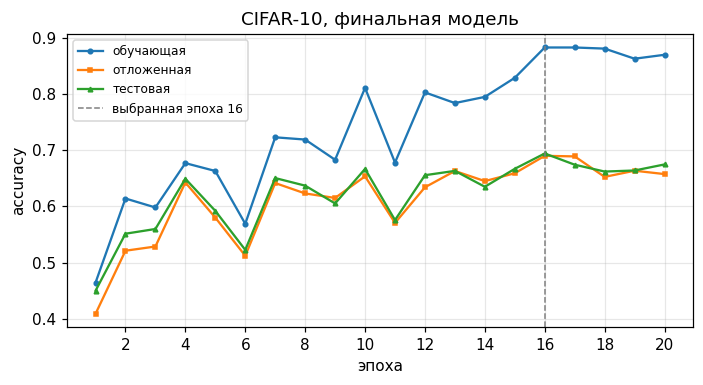

In [12]:
(Xb, yb), (Xbv, ybv), _ = split('CIFAR-10', 15000, 2000, np.random.default_rng(1))
torch.manual_seed(20260905)
final = Net(**BASE).to(DEVICE)
hist = run(final, Xb, yb, Xbv, ybv, lr=LR, epochs=20, Xtest=Xct, ytest=yct, keep_best=True)
best_ep = int(hist['val'].argmax()) + 1
print(f'лучшая эпоха по отложенной выборке: {best_ep}, accuracy на отложенной '
      f'{hist["val"][best_ep - 1]:.4f}, на тестовой (10000) {hist["test"][best_ep - 1]:.4f}')
print(f'число параметров: {n_params(final):,}')

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ep = range(1, 21)
ax.plot(ep, hist['train'], marker='o', ms=3, label='обучающая')
ax.plot(ep, hist['val'], marker='s', ms=3, label='отложенная')
ax.plot(ep, hist['test'], marker='^', ms=3, label='тестовая')
ax.axvline(best_ep, color='gray', ls='--', lw=1, label=f'выбранная эпоха {best_ep}')
ax.set_xlabel('эпоха'); ax.set_ylabel('accuracy'); ax.set_xticks(range(2, 21, 2))
ax.set_title('CIFAR-10, финальная модель'); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 10. Сравнение с неостаточными сетями на трёх выборках

In [13]:
rows = []
for ds in ['CIFAR-10', 'FashionMNIST', 'MNIST']:
    (Xa, ya), (Xav, yav), (Xat, yat) = split(ds, 5000, 2000, np.random.default_rng(20260905))
    in_ch, size = Xa.shape[1], Xa.shape[2]
    for net_name in ['лаб. 5 (Conv-ReLU-MaxPool)', 'plain', 'residual', 'bottleneck']:
        torch.manual_seed(20260905)
        if net_name.startswith('лаб. 5'):
            model, lr = ConvNet(in_ch=in_ch, size=size), 0.01
        else:
            model, lr = Net(**{**BASE, 'kind': net_name}, in_ch=in_ch), LR
        model = model.to(DEVICE)
        h = run(model, Xa, ya, Xav, yav, lr=lr, epochs=EPOCHS, keep_best=True)
        best = int(h['val'].argmax())
        rows.append(dict(dataset=ds, сеть=net_name, best_epoch=best + 1,
                         train_acc=float(h['train'][best]), val_acc=float(h['val'][best]),
                         test_acc=evaluate(model, Xat, yat), params=n_params(model)))
cmp = pd.DataFrame(rows)
cmp.to_csv('results_comparison.csv', index=False)
print(cmp.round(4).to_string(index=False))

     dataset                       сеть  best_epoch  train_acc  val_acc  test_acc  params
    CIFAR-10 лаб. 5 (Conv-ReLU-MaxPool)           6      0.642   0.5295    0.5066   14074
    CIFAR-10                      plain          10      0.658   0.5780    0.5681  205706
    CIFAR-10                   residual           9      0.702   0.5890    0.5862  205706
    CIFAR-10                 bottleneck           7      0.554   0.5130    0.4928   31978
FashionMNIST лаб. 5 (Conv-ReLU-MaxPool)           9      0.913   0.8565    0.8590   11274
FashionMNIST                      plain           6      0.873   0.8315    0.8301  205130
FashionMNIST                   residual           8      0.903   0.8550    0.8404  205130
FashionMNIST                 bottleneck           9      0.878   0.8320    0.8264   31402
       MNIST лаб. 5 (Conv-ReLU-MaxPool)          10      0.999   0.9710    0.9728   11274
       MNIST                      plain           6      0.993   0.9830    0.9799  205130
       MNI